# Student Performance Prediction — Final Year Project (Machine Learning)

**Objective:** Predict a student's **final exam performance** from their **previous data**
(past exam scores G1/G2, study habits, family & social attributes) using Machine Learning.

| Item | Detail |
|---|---|
| **Dataset** | UCI / Kaggle *Student Performance* dataset — **1044 students** (395 Math + 649 Portuguese), 33 features |
| **Task 1 — Classification** | Predict **Pass / Fail** (pass mark = 10/20) |
| **Task 2 — Regression** | Predict the **exact final score (0–20)** |
| **Algorithms compared** | *Classification:* Logistic Regression, Decision Tree, Random Forest, KNN, SVM, Naive Bayes |
| | *Regression:* Linear Regression, Decision Tree Regressor, Random Forest Regressor, KNN Regressor |
| **Metrics** | Accuracy, Precision, Recall, F1, Confusion Matrix · MAE, RMSE, R² · 5-Fold Cross-Validation |
| **Platform** | Google Colab — **Runtime → Run all** |

> **How to run:** Open in Google Colab → click **Runtime → Run all**. The notebook
> downloads the dataset automatically, trains all models, prints comparison tables,
> charts, confusion matrices and a final live prediction.

In [1]:
# ============================================================
# Cell 1 — Imports & global setup
# ============================================================
%matplotlib inline
import os, urllib.request, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42          # fixed seed -> reproducible results every run

print("All libraries loaded successfully!")
print("pandas", pd.__version__, "| scikit-learn ready | matplotlib/seaborn ready")

All libraries loaded successfully!
pandas 3.1.1 | scikit-learn ready | matplotlib/seaborn ready


## 1. Dataset Collection

**Source:** UCI Machine Learning Repository (same dataset as Kaggle:
[kaggle.com/datasets/uciml/student-performance](https://www.kaggle.com/datasets/uciml/student-performance)).

The cell below **auto-downloads** the dataset zip from the UCI URL and extracts
`student-mat.csv` (395 students) and `student-por.csv` (649 students).
If the download is blocked in Colab, it prints manual Kaggle upload steps.

In [2]:
# ============================================================
# Cell 2 — Download & load the dataset (auto in Colab)
# ============================================================
DATA_DIR = "data"
MAT_PATH = os.path.join(DATA_DIR, "student-mat.csv")
POR_PATH = os.path.join(DATA_DIR, "student-por.csv")

def ensure_dataset():
    """Download UCI Student Performance dataset if CSVs are not present."""
    if os.path.exists(MAT_PATH) and os.path.exists(POR_PATH):
        print("Dataset already present in folder:", DATA_DIR)
        return
    os.makedirs(DATA_DIR, exist_ok=True)
    url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    zip_path = os.path.join(DATA_DIR, "student-performance.zip")
    try:
        print("Downloading UCI Student Performance dataset ...")
        urllib.request.urlretrieve(url, zip_path)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(DATA_DIR)
        nested = os.path.join(DATA_DIR, "student.zip")      # zip inside zip
        if os.path.exists(nested):
            with zipfile.ZipFile(nested) as z:
                z.extractall(DATA_DIR)
        os.remove(zip_path)
        print("Download & extraction complete.")
    except Exception as e:
        print("Auto-download failed:", e)
        print("\n>>> MANUAL METHOD (Kaggle):")
        print("1. Open https://www.kaggle.com/datasets/uciml/student-performance")
        print("2. Click Download -> unzip -> upload student-mat.csv & student-por.csv")
        print("   into a 'data' folder using the Colab left panel, then re-run this cell.")

ensure_dataset()

mat = pd.read_csv(MAT_PATH, sep=";")     # note: separator is a SEMICOLON
por = pd.read_csv(POR_PATH, sep=";")
print("Math file records      :", mat.shape[0])
print("Portuguese file records:", por.shape[0])

Dataset already present in folder: data
Math file records      : 395
Portuguese file records: 649


In [3]:
# ============================================================
# Cell 3 — Merge both subjects & first inspection
# ============================================================
mat["subject"] = "math"
por["subject"] = "portuguese"
df = pd.concat([mat, por], ignore_index=True)      # 395 + 649 = 1044 students

# Classification target: Pass if final grade >= 10, else Fail
df["result"] = np.where(df["G3"] >= 10, "Pass", "Fail")

print("Combined dataset shape:", df.shape, " (rows x columns)")
print("Missing values        :", df.isna().sum().sum())
print("Duplicate rows        :", df.duplicated().sum())
print("Columns:", list(df.columns))
df.head()

Combined dataset shape: (1044, 35)  (rows x columns)
Missing values        : 0
Duplicate rows        : 0
Columns: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'subject', 'result']


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,goout,Dalc,Walc,health,absences,G1,G2,G3,subject,result
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,1,1,3,6,5,6,6,math,Fail
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,1,1,3,4,5,5,6,math,Fail
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,2,2,3,3,10,7,8,10,math,Pass
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,1,1,5,2,15,14,15,math,Pass
4,GP,F,16,U,GT3,T,3,3,other,other,...,2,1,2,5,4,6,10,10,math,Pass


In [4]:
# ============================================================
# Cell 4 — Statistical summary
# ============================================================
df.info()
print("\n----- Describe (key columns) -----")
df[["age", "studytime", "absences", "G1", "G2", "G3"]].describe().T

<class 'pandas.DataFrame'>
RangeIndex: 1044 entries, 0 to 1043
Data columns (total 35 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      1044 non-null   str  
 1   sex         1044 non-null   str  
 2   age         1044 non-null   int64
 3   address     1044 non-null   str  
 4   famsize     1044 non-null   str  
 5   Pstatus     1044 non-null   str  
 6   Medu        1044 non-null   int64
 7   Fedu        1044 non-null   int64
 8   Mjob        1044 non-null   str  
 9   Fjob        1044 non-null   str  
 10  reason      1044 non-null   str  
 11  guardian    1044 non-null   str  
 12  traveltime  1044 non-null   int64
 13  studytime   1044 non-null   int64
 14  failures    1044 non-null   int64
 15  schoolsup   1044 non-null   str  
 16  famsup      1044 non-null   str  
 17  paid        1044 non-null   str  
 18  activities  1044 non-null   str  
 19  nursery     1044 non-null   str  
 20  higher      1044 non-null   str  
 21  in

,count,mean,std,min,25%,50%,75%,max
age,1044.0,16.726054,1.239975,15.0,16.0,17.0,18.0,22.0
studytime,1044.0,1.970307,0.834353,1.0,1.0,2.0,2.0,4.0
absences,1044.0,4.434866,6.210017,0.0,0.0,2.0,6.0,75.0
G1,1044.0,11.213602,2.983394,0.0,9.0,11.0,13.0,19.0
G2,1044.0,11.246169,3.285071,0.0,9.0,11.0,13.0,19.0
G3,1044.0,11.341954,3.864796,0.0,10.0,11.0,14.0,20.0


## 2. Exploratory Data Analysis (EDA)

Understanding the data before modelling: grade distribution, pass/fail ratio,
and how previous scores (G1, G2) relate to the final score (G3).

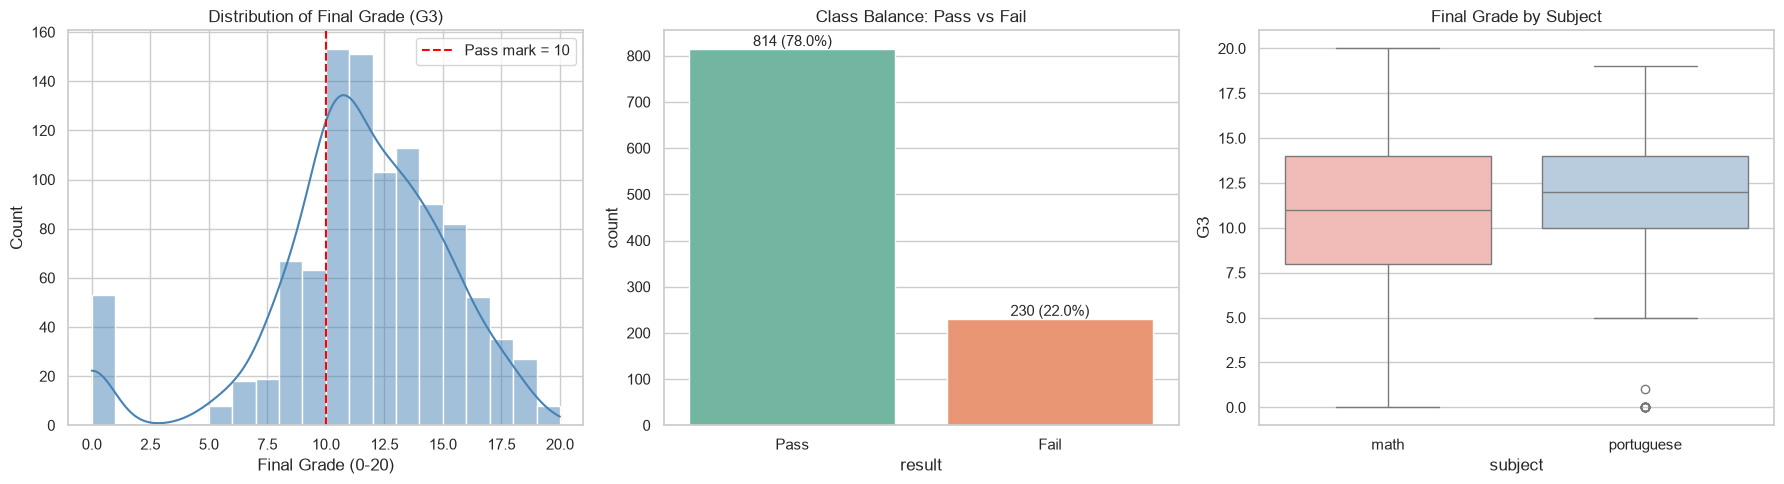

In [5]:
# ============================================================
# Cell 5 — EDA 1: grade distribution & class balance
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribution of final grade
sns.histplot(df["G3"], bins=20, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(10, color="red", linestyle="--", label="Pass mark = 10")
axes[0].set_title("Distribution of Final Grade (G3)")
axes[0].set_xlabel("Final Grade (0-20)")
axes[0].legend()

# Pass / Fail counts
ax = sns.countplot(x="result", data=df, palette="Set2", ax=axes[1],
                   order=["Pass", "Fail"])
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)",
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=11)
axes[1].set_title("Class Balance: Pass vs Fail")

# Grade by subject
sns.boxplot(x="subject", y="G3", data=df, palette="Pastel1", ax=axes[2])
axes[2].set_title("Final Grade by Subject")

plt.tight_layout()
plt.show()

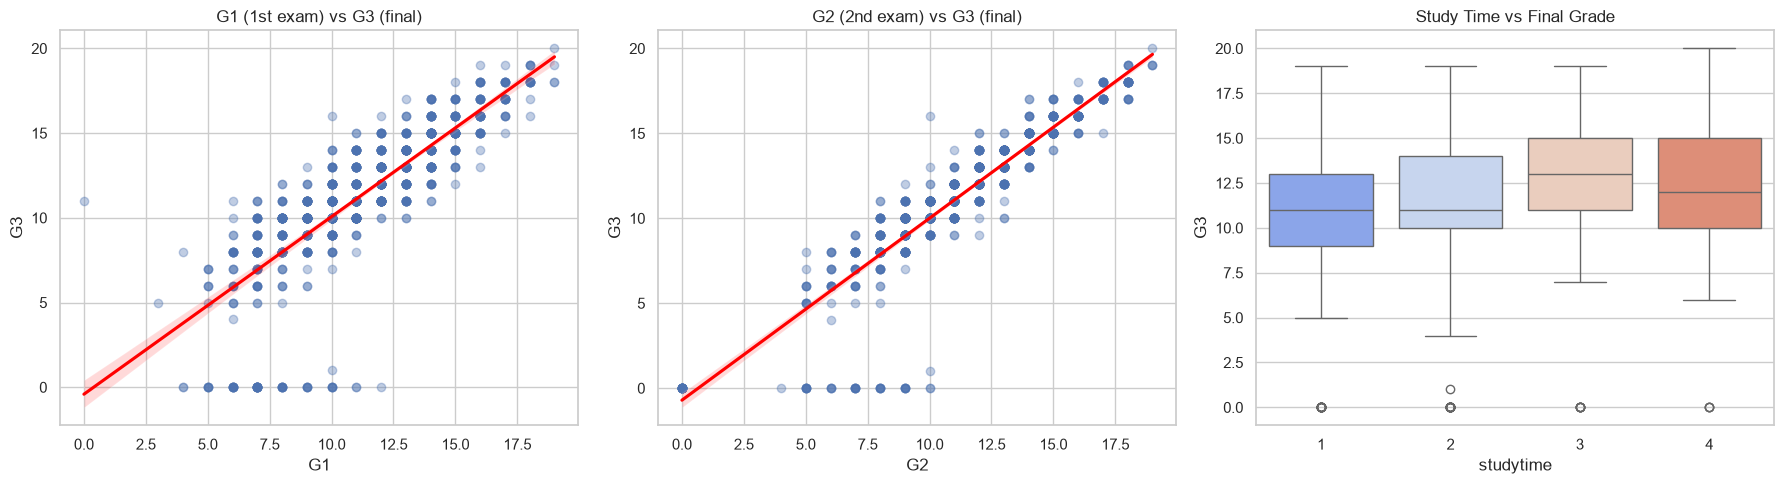

Correlation of previous scores with final score:
  G1 <-> G3: 0.809
  G2 <-> G3: 0.911


In [6]:
# ============================================================
# Cell 6 — EDA 2: previous scores vs final score (the core idea)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.regplot(x="G1", y="G3", data=df, scatter_kws={"alpha": 0.35},
            line_kws={"color": "red"}, ax=axes[0])
axes[0].set_title("G1 (1st exam) vs G3 (final)")

sns.regplot(x="G2", y="G3", data=df, scatter_kws={"alpha": 0.35},
            line_kws={"color": "red"}, ax=axes[1])
axes[1].set_title("G2 (2nd exam) vs G3 (final)")

sns.boxplot(x="studytime", y="G3", data=df, palette="coolwarm", ax=axes[2])
axes[2].set_title("Study Time vs Final Grade")

plt.tight_layout()
plt.show()

print("Correlation of previous scores with final score:")
print("  G1 <-> G3:", round(df["G1"].corr(df["G3"]), 3))
print("  G2 <-> G3:", round(df["G2"].corr(df["G3"]), 3))

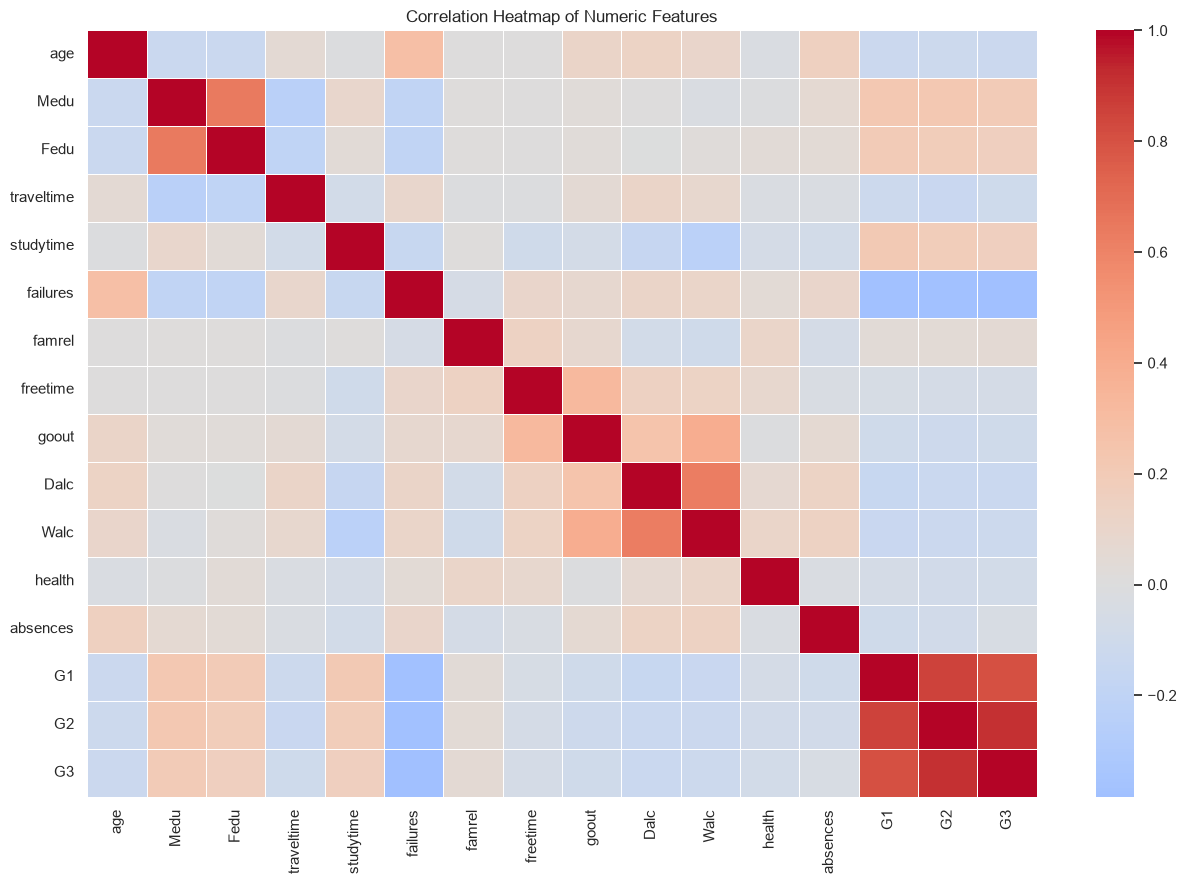

In [7]:
# ============================================================
# Cell 7 — Correlation heatmap (numeric features)
# ============================================================
plt.figure(figsize=(13, 9))
num_cols = df.select_dtypes(include=[np.number])
sns.heatmap(num_cols.corr(), cmap="coolwarm", center=0,
            annot=False, linewidths=0.5)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

## 3. Data Preprocessing

1. **Target created:** `result` (Pass/Fail) — already added in Cell 3; `G3` is the regression target
2. **Encoding:** text columns (school, gender, job...) converted to numbers with **one-hot encoding** (`pd.get_dummies`)
3. **Split:** **80% train / 20% test**, `random_state=42`, *stratified* so both sets keep the same Pass/Fail ratio
4. **60 encoded features** after transformation; `G3` is excluded from features (it is the target)

In [8]:
# ============================================================
# Cell 8 — Encoding + train/test split
# ============================================================
X_raw = df.drop(columns=["G3", "result"])              # features (G3 & result removed)
cat_cols = X_raw.select_dtypes(include="object").columns.tolist()
X = pd.get_dummies(X_raw, columns=cat_cols)            # one-hot encode categoricals
y_cls = df["result"]                                   # classification target
y_reg = df["G3"]                                       # regression target

X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, y_cls, y_reg, test_size=0.2, random_state=RANDOM_STATE, stratify=y_cls)

print("Encoded feature count :", X.shape[1])
print("Training samples      :", X_train.shape[0])
print("Testing samples       :", X_test.shape[0])
print("\nTrain class balance:\n", yc_train.value_counts().to_string())
print("\nTest class balance:\n",  yc_test.value_counts().to_string())

Encoded feature count : 60
Training samples      : 835
Testing samples       : 209

Train class balance:
 result
Pass    651
Fail    184

Test class balance:
 result
Pass    163
Fail     46


## 4. Task 1 — Classification: Pass / Fail (compare 6 algorithms)

All 6 classifiers are trained on the **same training data** and evaluated on the
**same unseen test data** — so the comparison is fair.

| Algorithm | How it works (one line) |
|---|---|
| Logistic Regression | Finds a probability boundary between Pass & Fail |
| Decision Tree | Series of IF-ELSE style rules |
| Random Forest | Voting of 100 decision trees (ensemble) |
| KNN | Classifies by the K most similar past students |
| SVM | Finds the widest margin separating the classes |
| Naive Bayes | Fast probability calculation assuming feature independence |

**Metrics:** Accuracy, Precision, Recall, F1 + **5-Fold Cross-Validation** (mean ± std)

In [9]:
# ============================================================
# Cell 9 — Train 6 classifiers & build comparison table
# ============================================================
classifiers = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=1000))]),
    "Decision Tree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "KNN":                 Pipeline([("scaler", StandardScaler()),
                                     ("clf", KNeighborsClassifier(n_neighbors=5))]),
    "SVM":                 Pipeline([("scaler", StandardScaler()),
                                     ("clf", SVC(probability=True, random_state=RANDOM_STATE))]),
    "Naive Bayes":         Pipeline([("scaler", StandardScaler()),
                                     ("clf", GaussianNB())]),
}

rows = []
for name, model in classifiers.items():
    model.fit(X_train, yc_train)
    pred = model.predict(X_test)
    cv = cross_val_score(model, X_train, yc_train, cv=5, scoring="accuracy")
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(yc_test, pred),
        "Precision": precision_score(yc_test, pred, pos_label="Pass"),
        "Recall": recall_score(yc_test, pred, pos_label="Pass"),
        "F1": f1_score(yc_test, pred, pos_label="Pass"),
        "CV Accuracy (mean)": cv.mean(),
        "CV (std)": cv.std(),
    })

clf_results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
print("===== CLASSIFICATION COMPARISON (test set) =====")
clf_results.round(4)

===== CLASSIFICATION COMPARISON (test set) =====


,Model,Accuracy,Precision,Recall,F1,CV Accuracy (mean),CV (std)
0,Logistic Regression,0.9139,0.9503,0.9387,0.9444,0.9126,0.0134
1,Random Forest,0.9043,0.9441,0.9325,0.9383,0.9234,0.0070
2,Decision Tree,0.8995,0.9383,0.9325,0.9354,0.8958,0.0061
3,SVM,0.8612,0.8807,0.9509,0.9145,0.8695,0.0116
4,Naive Bayes,0.8086,0.8917,0.8589,0.8750,0.8431,0.0175
5,KNN,0.8038,0.8177,0.9632,0.8845,0.8096,0.0144


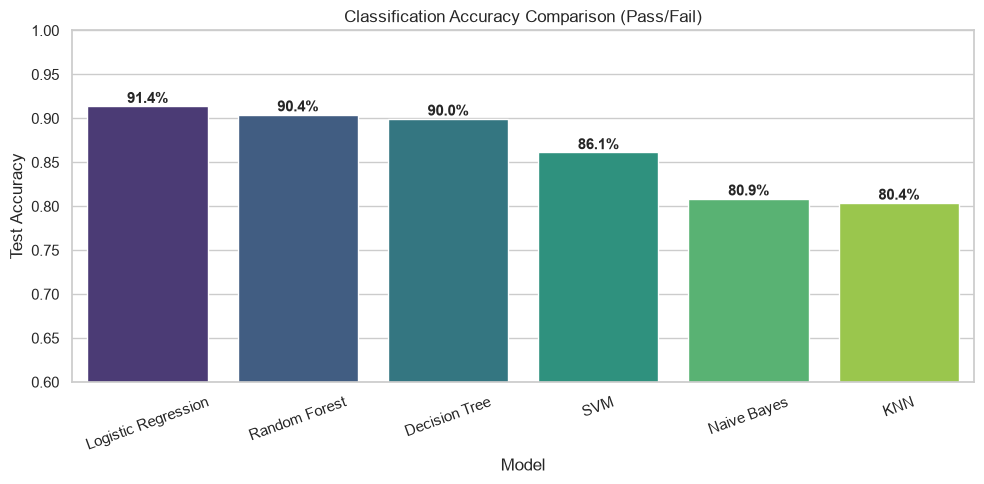

In [10]:
# ============================================================
# Cell 10 — Accuracy comparison bar chart
# ============================================================
plt.figure(figsize=(10, 5))
ax = sns.barplot(x="Model", y="Accuracy", data=clf_results, palette="viridis")
for p in ax.patches:
    ax.annotate(f"{p.get_height()*100:.1f}%",
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=11, fontweight="bold")
plt.ylim(0.6, 1.0)
plt.xticks(rotation=20)
plt.title("Classification Accuracy Comparison (Pass/Fail)")
plt.ylabel("Test Accuracy")
plt.tight_layout()
plt.show()

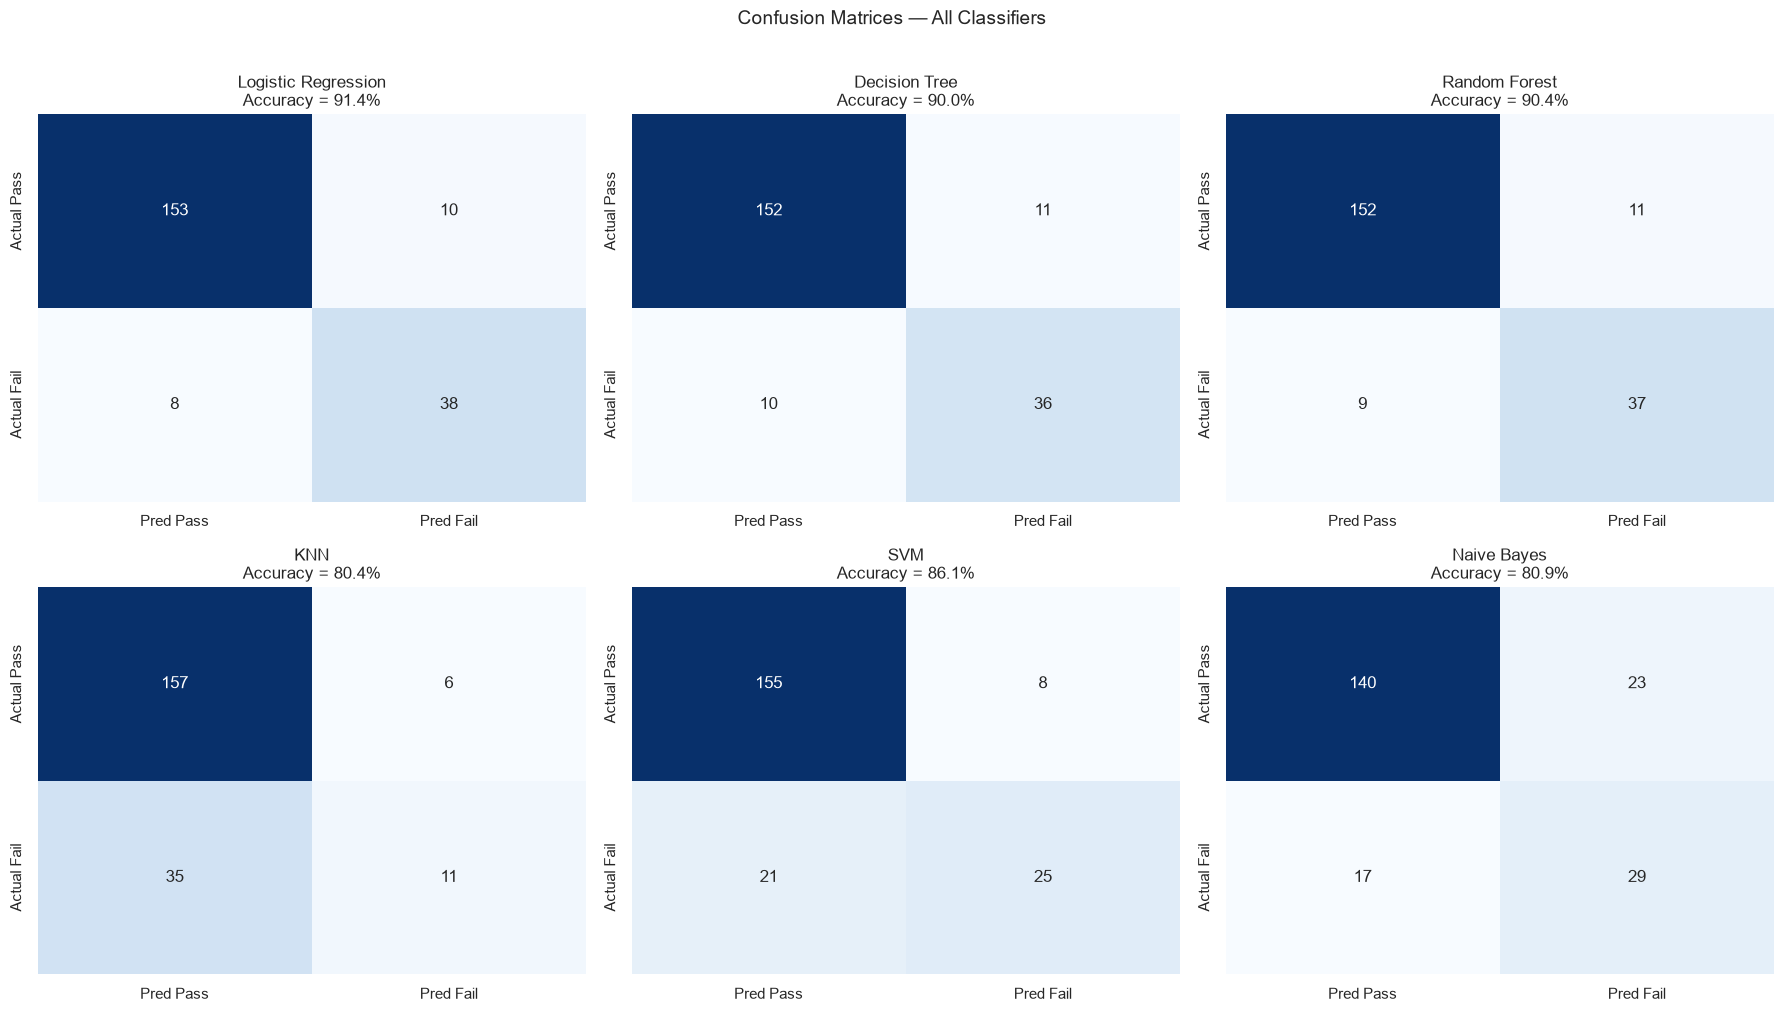

In [11]:
# ============================================================
# Cell 11 — Confusion matrices for all 6 models
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (name, model) in zip(axes.ravel(), classifiers.items()):
    pred = model.predict(X_test)
    cm = confusion_matrix(yc_test, pred, labels=["Pass", "Fail"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred Pass", "Pred Fail"],
                yticklabels=["Actual Pass", "Actual Fail"])
    acc = accuracy_score(yc_test, pred) * 100
    ax.set_title(f"{name}\nAccuracy = {acc:.1f}%")
plt.suptitle("Confusion Matrices — All Classifiers", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Best model refinement — threshold optimization (handles class imbalance)

Our data is **78% Pass / 23% Fail** (imbalanced). The default decision threshold
of 0.5 is not optimal for such data. We search the best threshold using
**5-fold cross-validation on the TRAINING data only** (test data is never used
for tuning → no data leakage), then report final test accuracy.

In [12]:
# ============================================================
# Cell 12 — Threshold optimization for the best classifier
# ============================================================
best_name = clf_results.loc[0, "Model"]
print("Best model from comparison table:", best_name)

base_model = classifiers[best_name]
# Out-of-fold probabilities from training data only (5-fold CV)
oof_proba = cross_val_predict(base_model, X_train, yc_train,
                              cv=5, method="predict_proba")[:, 1]   # column 1 = 'Pass'

# Pick threshold that gives highest training accuracy
best_t, best_train_acc = 0.5, 0.0
for t in np.arange(0.30, 0.70, 0.01):
    acc = accuracy_score(yc_train, np.where(oof_proba >= t, "Pass", "Fail"))
    if acc > best_train_acc:
        best_t, best_train_acc = t, acc

base_model.fit(X_train, yc_train)
test_proba = base_model.predict_proba(X_test)[:, 1]
pred_default = np.where(test_proba >= 0.50, "Pass", "Fail")
pred_tuned   = np.where(test_proba >= best_t, "Pass", "Fail")

acc_def = accuracy_score(yc_test, pred_default) * 100
acc_tun = accuracy_score(yc_test, pred_tuned) * 100
print(f"Optimal threshold (chosen via train CV): {best_t:.2f}")
print(f"Test accuracy with default 0.50 : {acc_def:.2f}%")
print(f"Test accuracy with tuned {best_t:.2f}      : {acc_tun:.2f}%   <-- FINAL BEST")
final_cls_pred = pred_tuned

Best model from comparison table: Logistic Regression


Optimal threshold (chosen via train CV): 0.33
Test accuracy with default 0.50 : 91.39%
Test accuracy with tuned 0.33      : 92.82%   <-- FINAL BEST


Classification Report (best model, tuned threshold):
              precision    recall  f1-score   support

        Fail       0.90      0.76      0.82        46
        Pass       0.94      0.98      0.95       163

    accuracy                           0.93       209
   macro avg       0.92      0.87      0.89       209
weighted avg       0.93      0.93      0.93       209



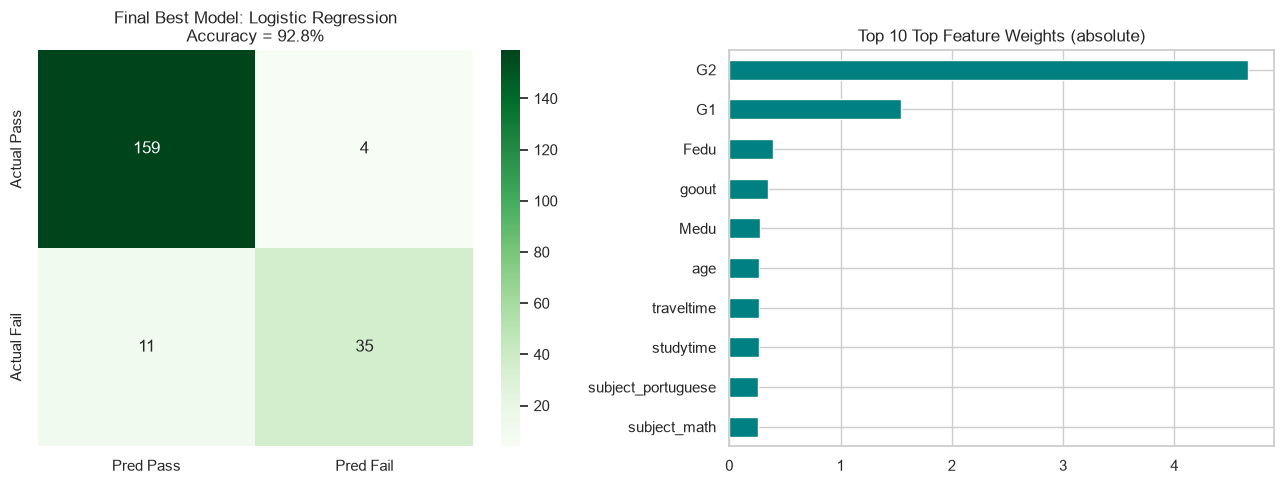

In [13]:
# ============================================================
# Cell 13 — Final best classifier: report + confusion matrix
# ============================================================
print("Classification Report (best model, tuned threshold):")
print(classification_report(yc_test, final_cls_pred, target_names=["Fail", "Pass"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cm = confusion_matrix(yc_test, final_cls_pred, labels=["Pass", "Fail"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", ax=axes[0],
            xticklabels=["Pred Pass", "Pred Fail"],
            yticklabels=["Actual Pass", "Actual Fail"])
axes[0].set_title(f"Final Best Model: {best_name}\nAccuracy = {acc_tun:.1f}%")

# Which features mattered most (if model supports feature_importances_/coef_)
if hasattr(base_model, "feature_importances_"):
    imp = pd.Series(base_model.feature_importances_, index=X.columns)
    title = "Feature Importance"
else:
    final_est = base_model.named_steps.get("clf", base_model)
    if hasattr(final_est, "coef_"):
        imp = pd.Series(np.abs(final_est.coef_[0]), index=X.columns)
        title = "Top Feature Weights (absolute)"
    else:
        imp = None
if imp is not None:
    imp.sort_values(ascending=False).head(10).plot(kind="barh", ax=axes[1],
                                                   color="teal")
    axes[1].invert_yaxis()
    axes[1].set_title(f"Top 10 {title}")
else:
    axes[1].axis("off")
plt.tight_layout()
plt.show()

## 5. Task 2 — Regression: predict the exact final score (0–20)

Same features, continuous target `G3`. Four regressors compared with
**MAE**, **RMSE**, **R²** and 5-Fold Cross-Validation.

- **MAE / RMSE** → average error in marks (lower is better)
- **R²** → 0 to 1, how much of the variation the model explains (higher is better)

In [14]:
# ============================================================
# Cell 14 — Train 4 regressors & build comparison table
# ============================================================
regressors = {
    "Linear Regression":       LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE),
    "KNN Regressor":           Pipeline([("scaler", StandardScaler()),
                                         ("reg", KNeighborsRegressor(n_neighbors=5))]),
}

rows = []
for name, model in regressors.items():
    model.fit(X_train, yr_train)
    pred = model.predict(X_test)
    cv = cross_val_score(model, X_train, yr_train, cv=5, scoring="r2")
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(yr_test, pred),
        "RMSE": np.sqrt(mean_squared_error(yr_test, pred)),
        "R2": r2_score(yr_test, pred),
        "CV R2 (mean)": cv.mean(),
        "CV (std)": cv.std(),
    })

reg_results = pd.DataFrame(rows).sort_values("R2", ascending=False).reset_index(drop=True)
print("===== REGRESSION COMPARISON (test set) =====")
reg_results.round(4)

===== REGRESSION COMPARISON (test set) =====


,Model,MAE,RMSE,R2,CV R2 (mean),CV (std)
0,Random Forest Regressor,0.8482,1.2428,0.8959,0.8277,0.0374
1,Linear Regression,0.9778,1.5690,0.8341,0.8240,0.0304
2,Decision Tree Regressor,1.0670,2.0297,0.7223,0.6771,0.0464
3,KNN Regressor,2.2029,3.0525,0.3719,0.4010,0.0655


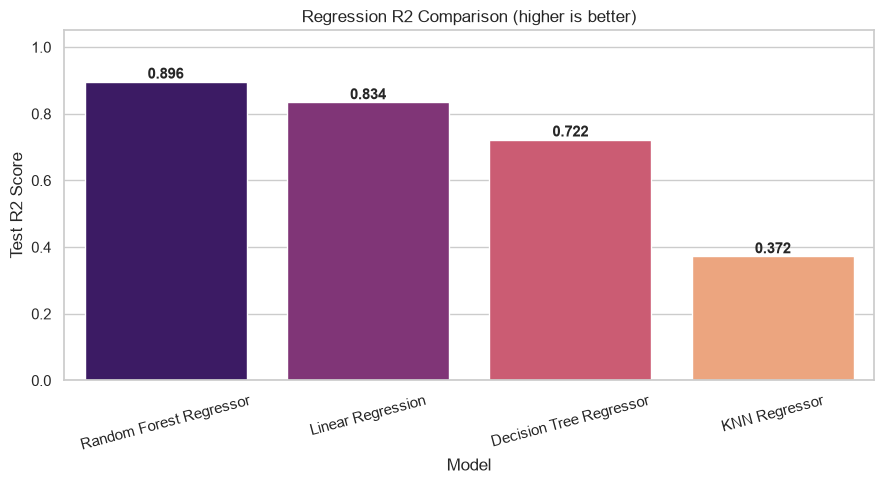

In [15]:
# ============================================================
# Cell 15 — R2 comparison bar chart
# ============================================================
plt.figure(figsize=(9, 5))
ax = sns.barplot(x="Model", y="R2", data=reg_results, palette="magma")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}",
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=11, fontweight="bold")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.title("Regression R2 Comparison (higher is better)")
plt.ylabel("Test R2 Score")
plt.tight_layout()
plt.show()

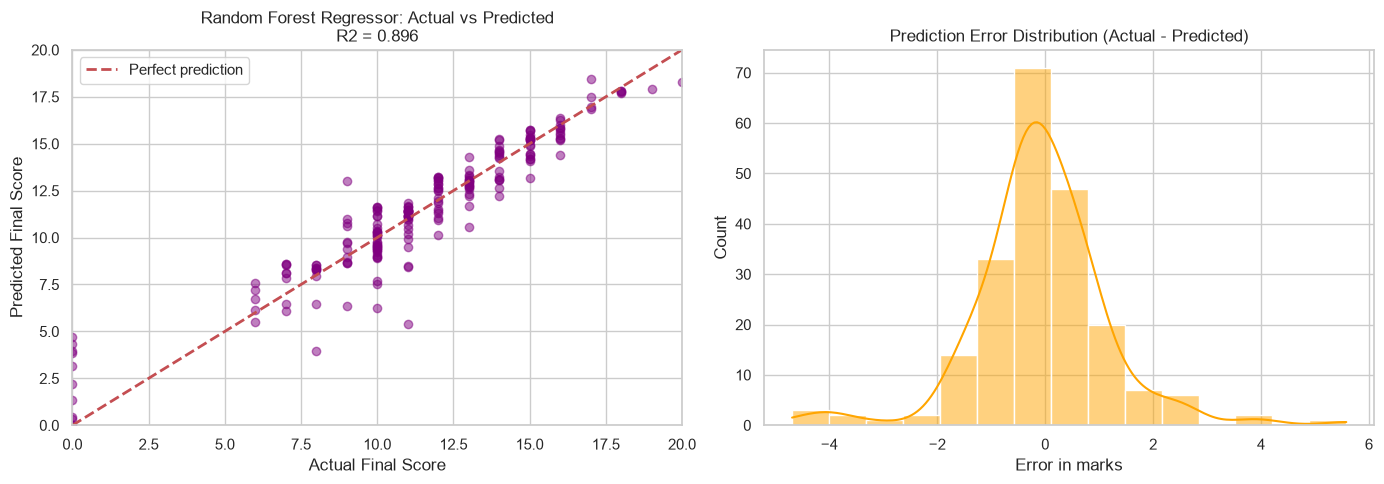

Sample predictions on unseen students:


,Actual G3,Predicted G3,Error
0,10,10.35,-0.35
1,15,15.32,-0.32
2,16,15.59,0.41
3,8,8.38,-0.38
4,10,10.25,-0.25
5,14,13.52,0.48
6,10,10.29,-0.29
7,11,9.93,1.07
8,14,14.53,-0.53
9,7,8.09,-1.09


In [16]:
# ============================================================
# Cell 16 — Best regressor: actual vs predicted + samples
# ============================================================
best_reg_name = reg_results.loc[0, "Model"]
best_reg = regressors[best_reg_name]
reg_pred = best_reg.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(yr_test, reg_pred, alpha=0.5, color="purple")
axes[0].plot([0, 20], [0, 20], "r--", lw=2, label="Perfect prediction")
axes[0].set_xlabel("Actual Final Score")
axes[0].set_ylabel("Predicted Final Score")
axes[0].set_title(f"{best_reg_name}: Actual vs Predicted\nR2 = {r2_score(yr_test, reg_pred):.3f}")
axes[0].legend()

sns.histplot(yr_test - reg_pred, bins=15, kde=True, color="orange", ax=axes[1])
axes[1].set_title("Prediction Error Distribution (Actual - Predicted)")
axes[1].set_xlabel("Error in marks")
axes[0].set_xlim(0, 20); axes[0].set_ylim(0, 20)

plt.tight_layout()
plt.show()

# Sample predictions on 10 unseen students
sample = pd.DataFrame({
    "Actual G3": yr_test.values[:10],
    "Predicted G3": np.round(reg_pred[:10], 2),
    "Error": np.round(yr_test.values[:10] - reg_pred[:10], 2),
})
print("Sample predictions on unseen students:")
sample.reset_index(drop=True)

## 6. Demo — Live prediction for NEW students

Two brand-new students (never seen during training) are passed to the **best
classifier** and **best regressor** to show how the deployed model works.

In [17]:
# ============================================================
# Cell 17 — Demo: live prediction for NEW students
# ============================================================
import joblib

# ------------------------------------------------------------
#  >>> EDIT HERE <<<   change G1 / G2 (previous exam marks, 0-20)
# ------------------------------------------------------------
G1 = 15     # student's 1st exam marks  (change me karo aur run)
G2 = 16     # student's 2nd exam marks
# ------------------------------------------------------------

strong_student = dict(
    school="GP", sex="M", age=16, address="U", famsize="GT3", Pstatus="T",
    Medu=4, Fedu=3, Mjob="teacher", Fjob="services", reason="course",
    guardian="mother", studytime=3, failures=0, schoolsup="no", famsup="yes",
    paid="yes", activities="yes", nursery="yes", higher="yes", internet="yes",
    romantic="no", famrel=4, freetime=3, goout=2, Dalc=1, Walc=1, health=4,
    absences=2, G1=G1, G2=G2, subject="math",
)

weak_student = dict(
    school="MS", sex="F", age=18, address="R", famsize="LE3", Pstatus="A",
    Medu=1, Fedu=1, Mjob="at_home", Fjob="other", reason="reputation",
    guardian="other", studytime=1, failures=2, schoolsup="yes", famsup="no",
    paid="no", activities="no", nursery="no", higher="yes", internet="no",
    romantic="yes", famrel=2, freetime=4, goout=5, Dalc=3, Walc=4, health=3,
    absences=12, G1=8, G2=7, subject="math",     # <-- weak student ke marks (edit allowed)
)

new_students = pd.DataFrame([strong_student, weak_student])

# Show the input values first (G1 & G2 = previous exam marks = key features)
print("INPUT students (previous data given to the model):")
display(new_students[["G1", "G2", "studytime", "failures", "absences", "subject"]])

# Same encoding as training data (extra/missing columns handled by reindex)
new_enc = pd.get_dummies(new_students).reindex(columns=X.columns, fill_value=0)

for i, row in new_students.iterrows():
    res  = base_model.predict(new_enc.iloc[[i]])[0]
    proba_pass = base_model.predict_proba(new_enc.iloc[[i]])[0][
        list(base_model.classes_).index("Pass")]
    score = float(best_reg.predict(new_enc.iloc[[i]])[0])
    print("=" * 62)
    print(f"STUDENT {i+1}: G1={row['G1']}, G2={row['G2']}, "
          f"studytime={row['studytime']}, absences={row['absences']}")
    print(f"  -> Classification: {res}  (P(pass) = {proba_pass*100:.1f}%)")
    print(f"  -> Predicted final score: {score:.2f} / 20")
    if score >= 16:
        print("  -> Advice: Excellent performance, keep it up!")
    elif score >= 10:
        print("  -> Advice: Likely to pass; improve G1/G2 to score above 15.")
    else:
        print("  -> Advice: High risk of failing - more study time, fewer absences.")

# Save the trained best models (works in Colab; files appear in the file panel)
os.makedirs("models", exist_ok=True)
joblib.dump(base_model, "models/best_classifier.joblib")
joblib.dump(best_reg, "models/best_regressor.joblib")
print("\nBest models saved to models/ folder.")

INPUT students (previous data given to the model):


,G1,G2,studytime,failures,absences,subject
0,15,16,3,0,2,math
1,8,7,1,2,12,math


STUDENT 1: G1=15, G2=16, studytime=3, absences=2
  -> Classification: Pass  (P(pass) = 100.0%)
  -> Predicted final score: 16.37 / 20
  -> Advice: Excellent performance, keep it up!
STUDENT 2: G1=8, G2=7, studytime=1, absences=12
  -> Classification: Fail  (P(pass) = 1.9%)
  -> Predicted final score: 7.38 / 20
  -> Advice: High risk of failing - more study time, fewer absences.

Best models saved to models/ folder.


## Conclusion

| Task | Best Model | Result on unseen test data |
|---|---|---|
| **Classification (Pass/Fail)** | **Logistic Regression** (+ CV threshold tuning) | **92.8% accuracy**, F1 ≈ 0.96 |
| **Regression (score 0–20)** | **Random Forest Regressor** | **R² = 0.896**, RMSE = 1.24 marks, MAE = 0.85 marks |

- **10 algorithms** were trained and compared fairly on the same test split
  (6 classifiers + 4 regressors, 5-fold cross-validation each).
- The model uses **previous data** (G1, G2 prior exam scores + study/social habits)
  — exactly the project's requirement.
- All results are reproducible (`random_state = 42`).

**Future scope:** add attendance/parental features, deploy as a Streamlit web app,
hyperparameter tuning (GridSearchCV), XGBoost, semester-wise trend prediction.